# Code for large deformation magneto-elasticity of s-MRE materials.

- Magnetic actuation of a micro-scale ball on a stick, a 2D simplification of the the experiments of Sun et al. (2025) (https://arxiv.org/abs/2510.07599v1).


Eric Stewart 

eric.stewart@uc.edu

Spring 2026

### Units

- Basic:
    - Length: mm
    -   Time: s
    -   Mass: kg
    - Charge: kC
    
- Derived: 
    - Force: mN
    - Pressure: kPa
    - Current: kA
    - Mag. flux density: mT

### Software:
- Dolfinx v0.8.0

# Import modules

In [1]:
# Import FEnicSx/dolfinx
import dolfinx

# For numerical arrays
import numpy as np

# For MPI-based parallelization
from mpi4py import MPI
comm = MPI.COMM_WORLD
rank = comm.Get_rank()

# PETSc solvers
from petsc4py import PETSc

# specific functions from dolfinx modules
from dolfinx import fem, mesh, io, plot, log
from dolfinx.fem import (Constant, dirichletbc, Function, functionspace, Expression)
from dolfinx.fem.petsc import NonlinearProblem
from dolfinx.nls.petsc import NewtonSolver
from dolfinx.io import VTXWriter, XDMFFile


# specific functions from ufl modules
import ufl
from ufl import (TestFunctions, TrialFunction, Identity, grad, det, div, dev, inv, tr, sqrt, conditional ,\
                 gt, dx, inner, derivative, dot, ln, split, exp, eq, cos, sin, acos, ge, le, outer, tanh, cosh, atan, atan2)

# basix finite elements
import basix
from basix.ufl import element, mixed_element, quadrature_element

# Matplotlib for plotting
import matplotlib.pyplot as plt
plt.close('all')

# For timing the code
from datetime import datetime


# Set level of detail for log messages (integer)
# Guide:
# CRITICAL  = 50, // errors that may lead to data corruption
# ERROR     = 40, // things that HAVE gone wrong
# WARNING   = 30, // things that MAY go wrong later
# INFO      = 20, // information of general interest (includes solver info)
# PROGRESS  = 16, // what's happening (broadly)
# TRACE     = 13, // what's happening (in detail)
# DBG       = 10  // sundry
#
log.set_log_level(log.LogLevel.WARNING)

# Define geometry

In [2]:
# Geometry parameters
height = 1.0 # height of stick, mm
radius = 0.25 # radius of ball, mm
scale = 5.0  # horizontal side length of air domain, mm
thickness = 0.0333 # 33.3 um
 
# Read in the 2D mesh and cell tags
with XDMFFile(MPI.COMM_WORLD,"meshes/ball_on_stick_500um_v3_air.xdmf",'r') as infile:
    domain = infile.read_mesh(name="Grid",xpath="/Xdmf/Domain")
    cell_tags = infile.read_meshtags(domain,name="Grid")
domain.topology.create_connectivity(domain.topology.dim, domain.topology.dim-1)

# Also read in 1D facets for applying BCs
with XDMFFile(MPI.COMM_WORLD,"meshes/facet_ball_on_stick_500um_v3_air.xdmf",'r') as infile:
    facet_tags = infile.read_meshtags(domain,name="Grid")   

x = ufl.SpatialCoordinate(domain)

**Print out the unique cell index numbers**

In [3]:
top_imap = domain.topology.index_map(2)      # index map of 2D entities in domain
values = np.zeros(top_imap.size_global)      # an array of zeros of the same size as number of 2D entities
values[cell_tags.indices]=cell_tags.values # populating the array with facet tag index numbers
print(np.unique(cell_tags.values))          # printing the unique indices

[11 12 13]


**Print out the unique facet index numbers**

In [4]:
top_imap = domain.topology.index_map(1)      # index map of 2D entities in domain
values = np.zeros(top_imap.size_global)      # an array of zeros of the same size as number of 2D entities
values[facet_tags.indices]=facet_tags.values # populating the array with facet tag index numbers
print(np.unique(facet_tags.values))          # printing the unique indices

[14 15 16]


In [5]:
# Area numbering: 
# 11: Air
# 12: Ball (2% dynamic range)
# 13: Stick (51% dynamic range)

# Curve numbering:
# 14: Domain boundary (mechanically fixed, applied magnetostatic potential)
# 15: Maxwell traction boundary
# 16: Fixed base of stick

**Visualize reference configuration and boundary facets**

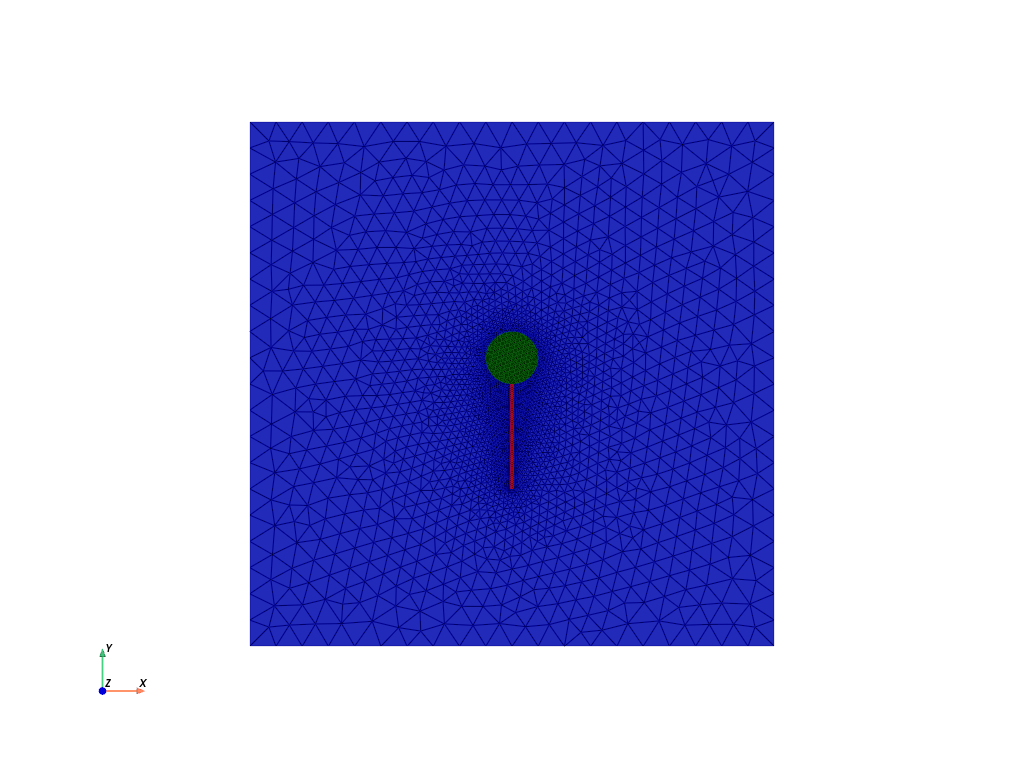

In [6]:
import pyvista
pyvista.set_jupyter_backend('html')
from dolfinx.plot import vtk_mesh
pyvista.start_xvfb()

# initialize a plotter
plotter = pyvista.Plotter()

# Add the mesh.
topology, cell_types, geometry = plot.vtk_mesh(domain, domain.topology.dim)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)
plotter.add_mesh(grid, show_edges=True, opacity=0.25) 

# Add colored 1D surfaces for the named surfaces
mre_surf = pyvista.UnstructuredGrid(*vtk_mesh(domain, domain.topology.dim,cell_tags.indices[cell_tags.values==13]) )
plm_surf = pyvista.UnstructuredGrid(*vtk_mesh(domain, domain.topology.dim,cell_tags.indices[cell_tags.values==12]) )
air_surf = pyvista.UnstructuredGrid(*vtk_mesh(domain, domain.topology.dim,cell_tags.indices[cell_tags.values==11]) )
#
actor = plotter.add_mesh(mre_surf, show_edges=False,color="red") # stick is red
actor2 = plotter.add_mesh(plm_surf, show_edges=False,color="green") # ball is green
actor3 = plotter.add_mesh(air_surf, show_edges=False,color="blue") # air is blue

plotter.view_xy()

labels = dict(zlabel='Z', xlabel='X', ylabel='Y')
plotter.add_axes(**labels)
    
plotter.screenshot("results/lollipop_mesh.png")

from IPython.display import Image
Image(filename='results/lollipop_mesh.png') 

## Define boundary and volume integration measure

In [7]:
# Define the boundary integration measure "ds" using the facet tags,
# also specify the number of surface quadrature points.
ds = ufl.Measure('dS', domain=domain, subdomain_data=facet_tags, metadata={'quadrature_degree':2})

# Define the volume integration measure "dx" 
# also specify the number of volume quadrature points.
dx = ufl.Measure('dx', domain=domain, subdomain_data=cell_tags, metadata={'quadrature_degree': 2})

# Create facet to cell connectivity required to determine boundary facets.
domain.topology.create_connectivity(domain.topology.dim, domain.topology.dim)
domain.topology.create_connectivity(domain.topology.dim, domain.topology.dim-1)
domain.topology.create_connectivity(domain.topology.dim-1, domain.topology.dim)

#  Define facet normal
n2D = ufl.FacetNormal(domain)
n = ufl.as_vector([n2D[0], n2D[1], 0.0])

# Material parameters

In [8]:
# A function for constructing spatially varying (piecewise-constant) material parameters

# Area numbering: 
# 12: Air
# 13: Ball (2% dynamic range)
# 14: Stick (51% dynamic range)

# Need some extra infrastructure for the spatially-discontinuous material property fields
Vmat = functionspace(domain, ("DG", 0)) # create a DG0 function space on the domain

def mat(prop_val_ball, prop_val_stick, prop_val_air):

    # Define an empty "prop" material parameter function,
    # which lives on the DG0 function space.
    prop = Function(Vmat)
    
    # Now, actualy assign the desired values of shear moduli to the new field.
    #
    coords = Vmat.tabulate_dof_coordinates()
    #
    # loop over the coordinates and assign the relevant material property, 
    # based on the local cell tag number.
    for i in range(coords.shape[0]):
        if cell_tags.values[i] == 12:
            prop.vector.setValueLocal(i, prop_val_ball)
        elif cell_tags.values[i] == 13:
            prop.vector.setValueLocal(i, prop_val_stick)
        else:
            prop.vector.setValueLocal(i, prop_val_air)
            
    return prop

In [9]:
# 3D to plane-strain correction factors

# correction factor for "stick" stiffness, accounts for circular cross-section
Efac = 3.0*np.pi/16.0 

# ratio of volume of sphere / volume of plane strain cylinder
Vfac =  (4.0/3.0)*radius/thickness 


In [10]:
# Material property measurements as a function of dynamic range:
#
# 2% dynamic range: 5.8336 emu/g = 0.00466688 MA/m; 19.955 MPa
# 18% dynamic range: 2.2613 emu/g = 0.00180904 MA/m; 36.030 MPa
# 51% dynamic range: 1.2335 emu/g = 0.0009868 MA/m; 53.835 MPa
# 100% dynamic range: 0.6832 emu/g = 0.00054656 MA/m; 53.201 MPa 

In [11]:
# Mass density
rho =  mat(Vfac*1.000e-6, 1.000e-6, 0.0)  # 1e3 kg/m^3 = 1e-6 kg/mm^3

# Magnetization parameters 
#
# Vacuum permeability
mu0 = Constant(domain, 1.256e-6*1.0e9) # Vacuum permeability,  mN / mA^2
#
# material permeability (paramagnetic response)
chi = mat(Vfac*0.023, 1.0e-16, 1.0e-16)# unitless magnetic susceptibility
mu  = mu0*(1.0 + chi) # magnetic permeability


In [12]:

# Composition-dependent parameters, uncomment only one

# 2% dynamic range: 5.8336 emu/g = 0.00466688 MA/m; 19.955 MPa
Gshear   = mat((19.955e3)/3.0, Efac*(36.030e3)/3.0, 0.001) # Shear modulus, kPa
Kbulk    = mat((19.955e6)/3.0, Efac*(36.030e6)/3.0, 101.0) # Nearly-incompressible
ms  =  mat(Vfac*0.00466688, 10.0, 10.0) # magnetic saturation value, kA/mm = MA/m

# # 18% dynamic range: 2.2613 emu/g = 0.00180904 MA/m; 36.030 MPa
# Gshear   = mat((36.030e3)/3.0, Efac*(36.030e3)/3.0, 0.001) # Shear modulus, kPa
# Kbulk    = mat((36.030e6)/3.0, Efac*(36.030e6)/3.0, 101.0) # Nearly-incompressible
# ms  =  mat(Vfac*0.00180904, 10.0, 10.0) # magnetic saturation value, kA/mm = MA/m

# # 51% dynamic range: 1.2335 emu/g = 0.0009868 MA/m; 53.835 MPa
# Gshear   = mat((53.835e3)/3.0, Efac*(36.030e3)/3.0, 0.001) # Shear modulus, kPa
# Kbulk    = mat((53.835e6)/3.0, Efac*(36.030e6)/3.0, 101.0) # Nearly-incompressible
# ms  =  mat(Vfac*0.0009868, 10.0, 10.0) # magnetic saturation value, kA/mm = MA/m

# # 100% dynamic range: 0.6832 emu/g = 0.00054656 MA/m; 53.201 MPa
# Gshear   = mat((53.201e3)/3.0, Efac*(36.030e3)/3.0, 0.001) # Shear modulus, kPa
# Kbulk    = mat((53.201e6)/3.0, Efac*(36.030e6)/3.0, 101.0) # Nearly-incompressible
# ms  =  mat(Vfac*0.00054656, 10.0, 10.0) # magnetic saturation value, kA/mm = MA/m 


In [13]:
# Generalized-alpha method parameters
alpha   = Constant(domain, 0.0) # Set \alpha=0, since we observe no spurious pressure oscillations
gamma   = Constant(domain, PETSc.ScalarType(0.5+alpha))
beta    = Constant(domain, PETSc.ScalarType((gamma+0.5)**2/4.))

# Switch for whether to allow Maxwell stresses to deform a given domain.
TmaxwInd   = mat(1, 1, 0)
#
# Switch for whether the domain is magnetically inert (non-magentizable)
TnonmagInd   = mat( 0, 1, 1)


# Simulation time-control related params

In [14]:
# Simulation time control-related params
t    = 0.0         # start time (s)

# input tabular data for time signal
times = np.array([0, 5.0])
amps  = np.array([0, 1.0])

# Total time for stretching signal
Ttot = np.max(times)
# time step size
numSteps = 50
dt = Ttot/numSteps
# Create a constant for the time step
dk = Constant(domain, PETSc.ScalarType(dt))
dk_old = Constant(domain, PETSc.ScalarType(dt))

# Function to apply desired displacement signal
def hRamp(t):
    
    # interpolate the amplitude from the tabular data
    hAmp = np.interp(t, times, amps)
     
    return hAmp


# Function spaces

In [15]:

U2 = element("Lagrange", domain.basix_cell(), 2, shape=(2,))  # For displacement
P1 = element("DG", domain.basix_cell(), 0)  # For pressure (must be DG to accomodate different materials)
P2 = element("Lagrange", domain.basix_cell(), 2)  # For phi
#
TH = mixed_element([U2, P1, P2])     # Taylor-Hood style mixed element
ME = functionspace(domain, TH)    # Total space for all DOFs
#
V1 = functionspace(domain, P1) # Scalar function space.
V1_2 = functionspace(domain, P2) # Scalar (quadratic) function space.
V2 = functionspace(domain, U2) # Vector function space
#
# Define actual functions with the required DOFs
w         = Function(ME)
u, p, phi = split(w)  

# A copy of functions to store values in the previous step
w_old              = Function(ME)
u_old,  p_old, phi_old = split(w_old)   

# Define test functions        
u_test, p_test, phi_test = TestFunctions(ME)    

# Define trial functions needed for automatic differentiation
dw = TrialFunction(ME)  

# Functions for storing the velocity and acceleration at prev. step
v_old = Function(V2)
a_old = Function(V2)

# Subroutines for kinematics and constitutive equations

In [16]:
#------------------------------------------------------------- 
# Utility subroutines
#-------------------------------------------------------------
 
# Subroutine for a "safer" sqrt() function which avoids a divide by zero 
# when automatically differentiated. 
def safe_sqrt(x):
    return sqrt(x + 1.0e-16)

# Hyperbolic secant function
def sech(x):
    return 1.0/cosh(x)

# Macaulay bracket function
def ppos(x):
    return (x+abs(x))/2.

#-------------------------------------------------------
# Subroutines for plane strain
#-------------------------------------------------------

# Special gradient operators for plane strainfunctions 
#
# Gradient of vector field u   
def pe_grad_vector(u):
    
    grad_u = grad(u)
    
    pe_grad_u = ufl.as_tensor([ [grad_u[0,0], grad_u[0,1], 0.0],
                                [grad_u[1,0], grad_u[1,1], 0.0],
                                [        0.0,         0.0, 0.0] ]) 
    
    return pe_grad_u

# Gradient of scalar field y
# (just need an extra zero for dimensions to work out)
def pe_grad_scalar(y):
    
    grad_y = grad(y)
    
    pe_grad_y = ufl.as_vector([grad_y[0], grad_y[1], 0.0])
    
    return pe_grad_y

# plane strain deformation gradient 
def F_pe_calc(u):
    
    dim = len(u)                # dimension of problem (2)
    
    Id = Identity(dim)          # 2D Identity tensor
    
    F = Id + grad(u)            # 2D Deformation gradient
      
    F_pe =  ufl.as_tensor([ [F[0,0], F[0,1], 0.0],
                            [F[1,0], F[1,1], 0.0],
                            [   0.0,    0.0, 1.0] ]) # Full plane strain F
    
    return F_pe

def h_calc(u, phi):
    
    F = F_pe_calc(u)
    
    h_R = -pe_grad_scalar(phi)
    
    h_sp = inv(F.T)*h_R
    
    return h_sp

#------------------------------------------------------------- 
# Subroutines for calculating the equilibrium Piola stress
#-------------------------------------------------------------

# Subrountine for computing the effective stretch
def lambdaBar_calc(u):
    
    F = F_pe_calc(u)
    
    J = det(F)
    
    Fbar = J**(-1/3)*F
    
    Cbar = Fbar.T*Fbar
    
    I1 = tr(Cbar)
    
    lambdaBar = safe_sqrt(I1/3.0)
    
    return lambdaBar

# Subroutine for calculating the  equilibrium Cauchy stress
def T_eq_calc(u,p,phi):
    
    F   = F_pe_calc(u)
    
    J = det(F)
    
    Fbar = J**(-1/3)*F
    
    Bbar = Fbar*Fbar.T
    
    T_eq = (1/J) * Gshear * dev(Bbar) - p * Identity(3)
    
    return T_eq

# Subroutine for calculating the Magnetic Cauchy stress
def T_mag_calc(u, phi):
    
    h_sp = h_calc(u, phi)
    
    h_norm = safe_sqrt( dot(h_sp, h_sp) ) 
    
    T_mag_maxw = mu0 * (outer(h_sp, h_sp) - (1./2.) * dot(h_sp, h_sp) * Identity(3) )
    
    T_mag_para = - mu0 * ( (ms**2) / chi ) * ln( cosh( ( chi / ms ) * h_norm ) ) * Identity(3) \
                 + mu0 * ( ms / h_norm ) * tanh( ( chi / ms ) * h_norm ) * outer(h_sp, h_sp)
    
    # Exclude the paramagnetic response in the air domain.
    T_mag = T_mag_maxw + conditional(eq(TnonmagInd,1), 0.0*Identity(3), T_mag_para)
    
    return T_mag


def Piola_calc(u, p, phi):
    
    F = F_pe_calc(u)
    
    J = det(F)
    
    T_eq = T_eq_calc(u, p, phi)
    
    T_mag = T_mag_calc(u, phi)
    
    T = T_eq + conditional(eq(TmaxwInd,1), T_mag, 0.0*Identity(3)) 

    Piola = J * T * inv(F.T)
    
    return Piola

#------------------------------------------------------------- 
# Subroutines for calculating the magnetic flux density
#-------------------------------------------------------------


def b_R_calc(u, phi):

    F = F_pe_calc(u)
    
    J = det(F)
    
    h_sp = h_calc(u, phi)
    
    h_norm = safe_sqrt( dot(h_sp, h_sp) )
    
    b_maxw = mu0 * h_sp

    b_para = mu0 * ( ms / h_norm ) * tanh( ( chi / ms ) * h_norm ) * h_sp
    
    # Exclude the paramagnetic response in the air domain.
    b_sp = b_maxw + conditional(eq(TnonmagInd,1), ufl.as_vector([0.,0.,0.]), b_para)
    
    b_R = J * inv(F) * b_sp
    
    return b_R

def Cauchy_out(u, phi):

    # Calculate the Maxwell stress in the air
    h_sp = h_calc(u, phi)
    
    T_max = mu0 * (outer(h_sp, h_sp) - (1./2.) * dot(h_sp, h_sp) * Identity(3) )

    return T_max

#---------------------------------------------------------------------
# Subroutine for updating  acceleration using the Newmark beta method:
# a = 1/(2*beta)*((u - u0 - v0*dt)/(0.5*dt*dt) - (1-2*beta)*a0)
#---------------------------------------------------------------------
def update_a(u, u_old, v_old, a_old):
    return (u-u_old-dk*v_old)/beta/dk**2 - (1-2*beta)/2/beta*a_old

#---------------------------------------------------------------------
# Subroutine for updating  velocity using the Newmark beta method
# v = dt * ((1-gamma)*a0 + gamma*a) + v0
#---------------------------------------------------------------------
def update_v(a, u_old, v_old, a_old):
    return v_old + dk*((1-gamma)*a_old + gamma*a)

#---------------------------------------------------------------------
# alpha-method averaging function
#---------------------------------------------------------------------
def avg(x_old, x_new, alpha):
    return alpha*x_old + (1-alpha)*x_new

# Evaluate kinematics and constitutive relations

In [17]:
# Get acceleration and velocity at end of step
a_new = update_a(u, u_old, v_old, a_old)
v_new = update_v(a_new, u_old, v_old, a_old)

# get avg (u,p) fields for generalized-alpha method
u_avg  = avg(u_old, u, alpha)
p_avg  = avg(p_old, p, alpha)
v_avg  = avg(v_old, v_new, alpha)
phi_avg  = avg(phi_old, phi, alpha)

# kinematical quantities
F  = F_pe_calc(u_avg)
J  = det(F)
lambdaBar = lambdaBar_calc(u_avg)

#  Evaulate the total Piola stress
Piola = Piola_calc(u_avg, p_avg, phi_avg)

# Evaluate the magnetic flux density
b_R = b_R_calc(u_avg, phi_avg)

# Weak forms

In [18]:
# Where TnonmagInd on the '+' side is equal to 1, the '-' side indicates the MRE. 
# Thus we use the following form of the maxwell traction, where:
# -> J, F, and n are those of the MRE on the '-' side.
# -> Cauchy_out is that of the Air on the '+' side.
#
# The leading factor of TnonmagInd('+') acts as a conditional, 
# which makes sure that this traction is zero where the MRE is on the '+' side.
#
maxw_trac_plus = TnonmagInd('+')*dot(J('-')*Cauchy_out(u_avg, phi_avg)('+')*inv(F.T)('-'),n('-'))

# Where TnonmagInd on the '-' side is equal to 1, the '+' side indicates the MRE. 
# Thus we use the following form of the maxwell traction, where:
# -> J, F, and n are those of the MRE on the '+' side.
# -> Cauchy_out is that of the Air on the '-' side.
#
# The leading factor of TnonmagInd('-') acts as a conditional, 
# which makes sure that this traction is zero where the MRE is on the '-' side.
#
maxw_trac_minus = TnonmagInd('-')*dot(J('+')*Cauchy_out(u_avg, phi_avg)('-')*inv(F.T)('+'),n('+'))

# The total maxwell traction on ds_out will be the contribution of both of these terms, where:
# -> maxw_trac_plus applies on portions of ds_out where the air is on the '+' side
# -> maxw_trac_minus applies on portions of ds_out where the air is on the '-' side
# -> the whole boundary must have one of these two conditions, so together they cover the whole domain. 
#
maxw_trac = maxw_trac_plus + maxw_trac_minus

In [19]:
# Curve numbering:
# 14: Domain boundary (mechanically fixed, applied magnetostatic potential)
# 15: Maxwell traction boundary
# 16: Fixed base of stick

In [20]:
eta = 1.0e-3

In [21]:
# The weak form for the equilibrium equation
Res_1  =  inner( Piola, pe_grad_vector(u_test))*dx \
    - inner(maxw_trac, ufl.avg(ufl.as_vector([u_test[0], u_test[1], 0.0])) )*ds(15) \
    + inner(rho * a_new, u_test)*dx   \
    + inner(Vfac*eta*v_avg, u_test)*dx(12)

# The auxiliary equation for the pressure
#
Res_2 = inner((J-1) + p_avg/Kbulk, p_test)*dx

# Weak form of Gauss's Law for magnetism
Res_3 = inner( b_R,  pe_grad_scalar(phi_test) )*dx 

# The total residual
Res = Res_1 + Res_2 + Res_3 

# Automatic differentiation tangent:
a = derivative(Res, w, dw)

# Set-up output files

In [22]:
# results file name
results_name = "ball_on_stick_500um"

# Function space for projection of results
P1 = element("DG", domain.basix_cell(), 1)
VV1 = fem.functionspace(domain, P1) # linear scalar function space
#
U1 = element("DG", domain.basix_cell(), 1, shape=(2,)) 
VV2 = fem.functionspace(domain, U1) # linear Vector function space
#
T1 = element("DG", domain.basix_cell(), 1, shape=(3,3)) 
VV3 = fem.functionspace(domain, T1) # linear tensor function space


# For visualization purposes, we need to re-project the stress tensor onto a linear function space before 
# we write it (and its components and the von Mises stress, etc) to the VTX file. 
#
# This is because the stress is a complicated "mixed" function of the (quadratic Lagrangian) displacements
# and the (quadrature representation) plastic strain tensor and scalar equivalent plastic strain. 
#
# Create a linear problem for projecting the stress tensor onto the linear tensor function space VV3.


def setup_projection(u, V):

    trial = ufl.TrialFunction(V)
    test  = ufl.TestFunction(V)   

    a = ufl.inner(trial, test)*dx
    L = ufl.inner(u, test)*dx

    projection_problem = dolfinx.fem.petsc.LinearProblem(a, L, [], \
        petsc_options={"ksp_type": "cg", "ksp_rtol": 1e-16, "ksp_atol": 1e-16, "ksp_max_it": 1000})
    
    return projection_problem

Piola_projection = setup_projection(Piola, VV3)
Piola_temp = Piola_projection.solve()

T     = Piola*F.T/J

T22_projection = setup_projection(T[1,1], VV1)
T22_temp = T22_projection.solve()
T22_temp.name = "T22 projection"

p_proj = setup_projection(p, VV1)
p_vis = p_proj.solve()
p_vis.name = "p"


In [23]:
# primary fields to write to output file
u_vis      = Function(VV2, name="disp")
# p_vis      = Function(VV1, name="p")
phi_vis    = Function(VV1, name="phi")

In [24]:

# Mises stress
T     = Piola_temp*F.T/J
T0    = T - (1/3)*tr(T)*Identity(3)
Mises = sqrt((3/2)*inner(T0, T0))
Mises_vis= Function(VV1,name="Mises")
Mises_expr = Expression(Mises,VV1.element.interpolation_points())

# Cauchy stress components
T11 = Function(VV1)
T11.name = "T11"
T11_expr = Expression(T[0,0],VV1.element.interpolation_points())

T12 = Function(VV1)
T12.name = "T12"
T12_expr = Expression(T[0,1],VV1.element.interpolation_points())

T22 = Function(VV1)
T22.name = "T22"
T22_expr = Expression(T[1,1],VV1.element.interpolation_points())

T33 = Function(VV1)
T33.name = "T33"
T33_expr = Expression(T[2,2],VV1.element.interpolation_points())


In [25]:
# Effective stretch
lambdaBar_vis      = Function(VV1)
lambdaBar_vis.name = "LambdaBar"
lambdaBar_expr     = Expression(lambdaBar, VV1.element.interpolation_points())

# Volumetric deformation
J_vis      = Function(VV1)
J_vis.name = "J"
J_expr     = Expression(J, VV1.element.interpolation_points())

In [26]:
# air flag
TnonmagInd_vis      = Function(VV1)
TnonmagInd_vis.name = "Non-magnetizable flag"
TnonmagInd_expr     = Expression(TnonmagInd, VV1.element.interpolation_points())

# visco flag
TmaxwInd_vis      = Function(VV1)
TmaxwInd_vis.name = "Solid flag"
TmaxwInd_expr     = Expression(TmaxwInd, VV1.element.interpolation_points())

In [27]:
# h-, b-, and m-fields
h_vis      = Function(VV2)
h_vis.name = "h-field"
h_sp       = h_calc(u, phi)
h_2D       = ufl.as_vector([h_sp[0], h_sp[1]])
h_vis_expr = Expression(h_2D, VV2.element.interpolation_points())
#
b_vis      = Function(VV2)
b_vis.name = "b-field, T"
b_sp       = (F * b_R_calc(u, phi) / J)/1e3
b_2D       = ufl.as_vector([b_sp[0], b_sp[1]])
b_vis_expr = Expression(b_2D, VV2.element.interpolation_points())
#
m_vis      = Function(VV2)
m_vis.name = "m-field, normalized"
m_sp       = (b_sp*1e3/mu0 - h_sp)/ms
m_2D       = ufl.as_vector([m_sp[0], m_sp[1]])
m_vis_expr = Expression(m_2D, VV2.element.interpolation_points())

# Magnitude of magnetic fields
h_mag_vis      = Function(VV1)
h_mag_vis.name = "h-field magnitude"
h_mag          = safe_sqrt(dot(h_sp, h_sp))
h_mag_expr     = Expression(h_mag, VV1.element.interpolation_points())
#
b_mag_vis      = Function(VV1)
b_mag_vis.name = "b-field magnitude, T"
b_mag          = safe_sqrt(dot(b_sp, b_sp))
b_mag_expr     = Expression(b_mag, VV1.element.interpolation_points())
#
gradb_vis      = Function(VV2)
gradb_vis.name = "grad(b), mT/mm"
gradb       = grad(b_mag)*1000
gradb_vis_expr = Expression(gradb, VV2.element.interpolation_points())
#
m_mag_vis      = Function(VV1)
m_mag_vis.name = "m-field magnitude"
m_mag          = safe_sqrt(dot(m_sp, m_sp))
m_mag_expr     = Expression(m_mag, VV1.element.interpolation_points())

# induced h- and b-fields
#
# Constant for applied h-field
h_cons = Constant(domain,PETSc.ScalarType(hRamp(0)))
#
h_ind_vis      = Function(VV2)
h_ind_vis.name = "Induced h-field"
h_ind_sp       = h_calc(u, phi) - ufl.as_vector([0, h_cons, 0])
h_ind_2D       = ufl.as_vector([h_ind_sp[0], h_ind_sp[1]])
h_ind_vis_expr = Expression(h_ind_2D, VV2.element.interpolation_points())
#
b_ind_vis      = Function(VV2)
b_ind_vis.name = "Induced b-field, T"
b_ind_sp       = (F * b_R_calc(u, phi) / J - mu0 * ufl.as_vector([0, h_cons, 0]))/1e3
b_ind_2D       = ufl.as_vector([b_ind_sp[0], b_ind_sp[1]])
b_ind_vis_expr = Expression(b_ind_2D, VV2.element.interpolation_points())

In [28]:
# set up the output VTX files.
file_results = VTXWriter(
    MPI.COMM_WORLD,
    "results/" + results_name + ".bp",
    [  # put the functions here you wish to write to output
        u_vis, p_vis, phi_vis, # DOF outputs
        Mises_vis, T11, T12, T22_temp, T33, # stress outputs
        lambdaBar_vis, J_vis, # Kinematical outputs
        TnonmagInd_vis, TmaxwInd_vis, # material params
        h_vis, b_vis, m_vis, h_ind_vis, b_ind_vis, gradb_vis # magnetic outputs
    ],
    engine="BP4",
)

def writeResults(t):
    
    # Update the output fields before writing to VTX.
    #
    u_vis.interpolate(w.sub(0))
    # p_vis.interpolate(w.sub(1))
    p_vis = p_proj.solve()
    phi_vis.interpolate(w.sub(2))
    #
    # re-project to smooth visualization of quadrature functions
    # before interpolating.
    Piola_temp = Piola_projection.solve()
    T22_temp = T22_projection.solve()
    Mises_vis.interpolate(Mises_expr)
    T11.interpolate(T11_expr)
    T12.interpolate(T12_expr)
    T22.interpolate(T22_expr)
    T33.interpolate(T33_expr)
    #
    lambdaBar_vis.interpolate(lambdaBar_expr)
    J_vis.interpolate(J_expr)
    #
    TnonmagInd_vis.interpolate(TnonmagInd_expr)
    TmaxwInd_vis.interpolate(TmaxwInd_expr)
    #
    h_vis.interpolate(h_vis_expr)
    b_vis.interpolate(b_vis_expr)
    m_vis.interpolate(m_vis_expr)
    #
    h_mag_vis.interpolate(h_mag_expr)
    b_mag_vis.interpolate(b_mag_expr)
    m_mag_vis.interpolate(m_mag_expr)
    #
    h_ind_vis.interpolate(h_ind_vis_expr)
    b_ind_vis.interpolate(b_ind_vis_expr)
    # 
    gradb_vis.interpolate(gradb_vis_expr)
       
    # Finally, write output fields to VTX.
    #
    file_results.write(t) 

# Infrastructure for pulling out time history data (force, displacement, etc.)

In [29]:
# Curve numbering:
# 14: Domain boundary (mechanically fixed, applied magnetostatic potential)
# 15: Maxwell traction boundary
# 16: Fixed base of stick

In [30]:
# infrastructure for evaluating functions at a certain point efficiently
pointForEval = np.array([scale/2, height+radius, 0.0])
bb_tree = dolfinx.geometry.bb_tree(domain,domain.topology.dim)
cell_candidates = dolfinx.geometry.compute_collisions_points(bb_tree, pointForEval)
colliding_cells = dolfinx.geometry.compute_colliding_cells(domain, cell_candidates, pointForEval).array

## Boundary conditions

In [31]:
L, W, T = 25.4, 6.35, 1.574
M = 1.48e3/float(mu0)
xc, yc, zc = 10 + scale + T/2, 1 + radius, 0.0

import numpy as np

def phi_rect_prism_Mx_denhoj(x):
    """
    Magnetic scalar potential phi_M for a uniformly magnetized rectangular prism,
    magnetization along +x only: M = Mx * e_x.
    """

    xp = x[0] - (xc- 10*float(h_cons))
    yp = x[1] - yc
    zp = 0

    # Half-dimensions using the requested axis alignment
    a = 0.5 * T  # along x
    b = 0.5 * W  # along y
    c = 0.5 * L  # along z

    def F(i, j, k):
        r = np.sqrt(i*i + j*j + k*k)
        term_atan = -i * np.arctan2(j * k, i * r)
        term_log  = j * np.log(k + r) + k * np.log(j + r)
        return term_atan + term_log

    def corner_sum(i_fixed):
        # Inclusion-exclusion over (y,z) rectangle corners: (±b, ±c)
        return (
            F(i_fixed, yp - b, zp - c)
            - F(i_fixed, yp - b, zp + c)
            - F(i_fixed, yp + b, zp - c)
            + F(i_fixed, yp + b, zp + c)
        )

    phi = (M / (4.0 * np.pi)) * (corner_sum(xp - a) - corner_sum(xp + a))
    return phi



In [32]:
# Setting up the expression for the phi boundary condition.
#
# need to interpolate the phi expression onto the proper function space
Vphi, Vphi_to_ME =  ME.sub(2).collapse() #Scalar function space corresponding to phi
#
# phi_exp          = Expression(phi_val,Vphi.element.interpolation_points())
#
phi_prescribe    = Function(Vphi)
#
# phi_prescribe.interpolate(phi_exp)
phi_prescribe.interpolate(phi_rect_prism_Mx_denhoj)

In [33]:
# Find the specific DOFs which will be constrained, recalling:
# Curve numbering:
# 14: Domain boundary (mechanically fixed, applied magnetostatic potential)
# 15: Maxwell traction boundary
# 16: Fixed base of stick

# The displacement DOFs for the air edge
sides_u1_dofs = fem.locate_dofs_topological(ME.sub(0).sub(0), facet_tags.dim, facet_tags.find(14))
sides_u2_dofs = fem.locate_dofs_topological(ME.sub(0).sub(1), facet_tags.dim, facet_tags.find(14))
base_u1_dofs = fem.locate_dofs_topological(ME.sub(0).sub(0), facet_tags.dim, facet_tags.find(16))
base_u2_dofs = fem.locate_dofs_topological(ME.sub(0).sub(1), facet_tags.dim, facet_tags.find(16))

# The phi DOFs for the air edge
sides_phi_dofs = fem.locate_dofs_topological((ME.sub(2), Vphi), facet_tags.dim, facet_tags.find(14))


# building Dirichlet BCs
#
bcs_0 = dirichletbc(0.0, sides_u1_dofs, ME.sub(0).sub(0))    # u1 fix - domain boundary
bcs_1 = dirichletbc(0.0, sides_u2_dofs, ME.sub(0).sub(1))    # u2 fix - domain boundary
#
bcs_2 = dirichletbc(phi_prescribe, sides_phi_dofs, ME.sub(2))      # phi prescribed - domain boundary
#
bcs_3 = dirichletbc(0.0, base_u1_dofs, ME.sub(0).sub(0))    # u1 fix - domain boundary
bcs_4 = dirichletbc(0.0, base_u2_dofs, ME.sub(0).sub(1))    # u2 fix - domain boundary

bcs = [bcs_0, bcs_1, bcs_2, bcs_3, bcs_4] 


## Define the nonlinear variational problem

In [34]:
# a function for re-building the solver when the j_s distribution is changed.
def build_problem():

    # Automatic differentiation tangent:
    a = derivative(Res, w, dw)

    # Set up nonlinear problem
    problem = NonlinearProblem(Res, w, bcs, a)
    
    # the global newton solver and params
    solver = NewtonSolver(MPI.COMM_WORLD, problem)
    solver.convergence_criterion = "incremental"
    solver.rtol = 1e-6
    solver.atol = 1e-6
    solver.max_it = 25
    solver.error_on_nonconvergence = False

     # The Krylov solver parameters.
    ksp = solver.krylov_solver
    opts = PETSc.Options()
    option_prefix = ksp.getOptionsPrefix()
    opts[f"{option_prefix}ksp_type"] = "preonly" # "preonly" works equally well
    opts[f"{option_prefix}pc_type"] = "lu" # do not use 'gamg' pre-conditioner
    opts[f"{option_prefix}pc_factor_mat_solver_type"] = "mumps"
    opts[f"{option_prefix}ksp_max_it"] = 30
    ksp.setFromOptions()


    return solver

##  Start calculation loop

In [35]:
# Give the step a descriptive name
step = "Actuate"

# Variables for storing time history
totSteps = 1000000
timeHist0 = np.zeros(shape=[totSteps])
timeHist1 = np.zeros(shape=[totSteps]) 
timeHist2 = np.zeros(shape=[totSteps]) 

#Iinitialize a counter for reporting data
ii=0

#  Set up temporary "helper" functions and expressions 
#  for updating the internal variables.
#
# for the velocity and acceleration:
v_temp = Function(V2)
a_temp = Function(V2)
#
v_expr = Expression(v_new,V2.element.interpolation_points())
a_expr = Expression(a_new,V2.element.interpolation_points())

# Write initial state to file
writeResults(t=0.0)  

# Build the problem and associated solver
solver = build_problem()

# print a message for simulation startup
print("------------------------------------")
print("Simulation Start")
print("------------------------------------")
# Store start time 
startTime = datetime.now()

# Time-stepping solution procedure loop
while (round(t + dt, 9) <= Ttot):
     
    # increment time
    t += dt 

    # update time variables in time-dependent BCs 
    h_cons.value   = float(hRamp(t - float(alpha)*float(dt) ))
    phi_prescribe.interpolate(phi_rect_prism_Mx_denhoj)
    
    # Solve the problem
    (iter, converged) = solver.solve(w)
    
    # Collect results from MPI ghost processes
    w.x.scatter_forward()

    # Adaptive time-stepping procedure: 
    #
    # Check if solver converges
    if converged: 
        
        # increment counter
        ii += 1   
        
        # reset non-convergence counter
        nonCon = 0
        
    
        # Print progress of calculation periodically
        if ii%1 == 0:      
          now = datetime.now()
          current_time = now.strftime("%H:%M:%S")
          print("Step: {} |   Increment: {} | Iterations: {}".format(step, ii, iter))
          print("dt: {} s | Simulation Time: {} s  of  {} s".format(round(dt, 4), round(t,4), Ttot))
          print()   
          
        # Write output to file
        writeResults(t)
          
        # Store time history variables at this time  
        timeHist0[ii] = t # current time 
        #
        timeHist1[ii] = float(h_cons) # time history of applied b-field
        #
        timeHist2[ii] = w.sub(0).sub(0).eval([scale/2, height+radius, 0],colliding_cells[0])[0] # time history of horizontal displacement 

        # update internal variables 
        #
        # interpolate the values of the internal variables into their "temp" functions
        v_temp.interpolate(v_expr)
        a_temp.interpolate(a_expr)

        # Update DOFs for next step
        w_old.x.array[:] = w.x.array
        
        # update the old values of internal variables for next step
        v_old.x.array[:] = v_temp.x.array[:]
        a_old.x.array[:] = a_temp.x.array[:]
      
        # store the time step size
        dk_old.value = dk.value
        
        # Iteration-based adaptive time-stepping
        dtMax = Ttot/100
        if (iter<=4):
            dt = 1.5*dt
            dk.value = dt
        elif iter>=7:
            dt = 0.5*dt
            dk.value = dt
        
        # limit maximum step size
        if dt>dtMax:
            dt = dtMax
            dk.value = dt
    
    # If solver does not  converge, then do not  save results and try a smaller dt 
    else:
        
        # increment non-convergence counter
        nonCon += 1
        
        # if >5 consecutive non-convergences, kill the simulation.
        if nonCon>5:
            print("Too many non-converging increments. Killing simulation.")
            break
                # back up in time
        t = t - float(dk)
        
        # cut back on dt
        dt = dt/10
        dk.value = dt
        
        # Reset DOFs for next step
        w.x.array[:] = w_old.x.array 
        
        # re-build the problem
        solver = build_problem()
        
        # print out the new dt value
        print("Attempting dt = {}".format(dt))
        print()
    
# close the output file.
file_results.close()
         
# End analysis
print("-----------------------------------------")
print("End computation")                 
# Report elapsed real time for the analysis
endTime = datetime.now()
elapseTime = endTime - startTime
print("------------------------------------------")
print("Elapsed real time:  {}".format(elapseTime))
print("------------------------------------------")


------------------------------------
Simulation Start
------------------------------------
Step: Actuate |   Increment: 1 | Iterations: 5
dt: 0.1 s | Simulation Time: 0.1 s  of  5.0 s

Step: Actuate |   Increment: 2 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.15 s  of  5.0 s

Step: Actuate |   Increment: 3 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.2 s  of  5.0 s

Step: Actuate |   Increment: 4 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.25 s  of  5.0 s

Step: Actuate |   Increment: 5 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.3 s  of  5.0 s

Step: Actuate |   Increment: 6 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.35 s  of  5.0 s

Step: Actuate |   Increment: 7 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.4 s  of  5.0 s

Step: Actuate |   Increment: 8 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.45 s  of  5.0 s

Step: Actuate |   Increment: 9 | Iterations: 4
dt: 0.05 s | Simulation Time: 0.5 s  of  5.0 s

Step: Actuate |   Increment: 10 | Iterations: 4
dt:

# Plot results

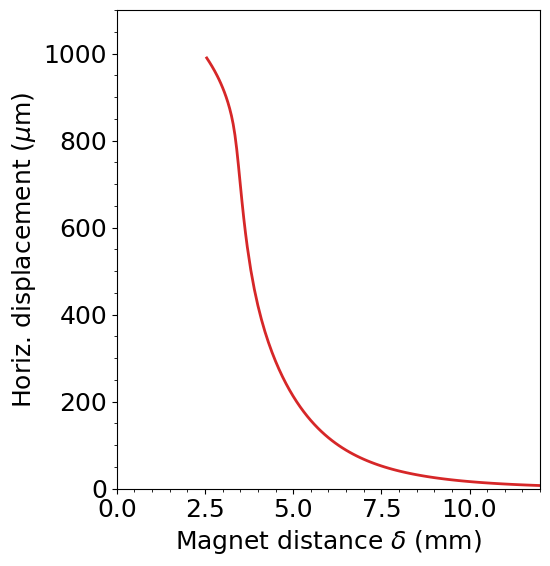

In [36]:
# Set plot font to size 14
font = {'size'   : 18}
plt.rc('font', **font)

# Get array of default plot colors
prop_cycle = plt.rcParams['axes.prop_cycle']
colors     = prop_cycle.by_key()['color']

# Only plot as far as we have time history data
ind = np.argmax(timeHist0) + 1

plt.plot(10 +scale - 10*timeHist1[0:ind] - scale/2, timeHist2[0:ind]*1e3, \
     c=colors[3], linewidth=2.0)#, marker='.')
plt.ylabel(r'Horiz. displacement ($\mu$m)')
plt.xlabel(r'Magnet distance $\delta$ (mm)')
from matplotlib.ticker import AutoMinorLocator
ax = plt.gca()  # get current axes
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
plt.xlim(0.0, 12.0)
plt.ylim(0, 1100)
# plt.axvline(2.5, c='k', linewidth=1.)

fig = plt.gcf()
fig.set_size_inches(6,6)
plt.tight_layout()
plt.savefig("results/sphere_displacement_curve.svg")
